### Here it is implemented the Krotov's method in different systems to simultaneously reach a high fidelity in a single-qubit quantum operation and prevent the system from populating higher energy levels. In this case, the X, Hadamard, ans S-phase gates are considered.

In [1]:
import numpy as np
from scipy.integrate import solve_ivp
from scipy.linalg import expm
from scipy.linalg import block_diag
import matplotlib.pyplot as plt
import qutip as qt
from numba import njit
import pandas as pd
import time
np.set_printoptions(formatter={'float': lambda x: format(x, '6.3E')})

Use this cell to define everything what will be required to specify during the simulation.

In [2]:
# Tf: Final time
# N: Number of time steps (assume a uniform time grid)
# qleak: leakage penalization factor
# alpha: updating factor in the Krotov method
# tol: tolerance for convergence in the Krotov method
# maxiter: maximum number of iterations in the Krotov method
# Ugate: quantum gate to generate. Current options are "X", "H", and "S".
# GlobPhase: set True to use the global-phase insensitive functional, and False to use zero-phase error.
# envelope: whether or not to use and envelope function for the Krotov update.

Thrlev = True  # Set to True for 3-level system, False for 4-level system

if (Thrlev):
    # 3-level system parameters
    prms = {"Tf": 10., "N": 1000, "qleak": 0., "alpha": 1., "tol":1.e-7, "maxiter": 200, "Ugate": "X", "GlobPhase": False, "envelope": False}
    def guess_ctrl(t):
        return np.cos(2*np.pi*t)*np.pi/prms["Tf"] *np.exp(-(t/prms["Tf"]-0.5)**2)
else:
    # 4-level system parameters
    prms = {"Tf": 3., "N": 100, "qleak": 0., "alpha": 0.1, "tol":1.e-3, "maxiter": 10000, "Ugate": "S", "GlobPhase": False, "envelope": False}
    def guess_ctrl(t):
        return 5*t*np.exp(-t*t)# np.exp(-(t-0.5*prms["Tf"])**2) *np.sin(10*np.pi*t/prms["Tf"])
    
#The envelope function, if required
def envel(t):
    tr = 0.01
    if t < tr:
        return np.sin(np.pi * t / (2 * tr)) ** 2
    elif tr < t < prms["Tf"] - tr:
        return 1.0
    else:
        return np.sin(np.pi * (t - prms["Tf"]) / (2 * tr)) ** 2

This cell sets up the problem.

In [18]:
if (Thrlev):
    Tf = prms["Tf"]
    N = prms["N"]
    dt = Tf/N
    dim = 3
    Nctrls = 1
    tgrid = dt*np.arange(0, N+1)
    midgrid = tgrid[0:N] + 0.5*dt*np.ones(N)
    midgrid = np.concatenate(([0.], midgrid, [Tf]))
    q = prms["qleak"]# The weight factor for the penalization of the occupancy of the state |2>

    if (prms["Ugate"] == "X"):
        Utgt = block_diag(np.array([[0, 1], [1, 0]], dtype=np.complex128), np.array([[1]], dtype=np.complex128))
    elif (prms["Ugate"] == "H"):
        Utgt = block_diag(np.sqrt(0.5)*np.array([[1, 1], [1, -1]], dtype=np.complex128), np.array([[1]], dtype=np.complex128))
    elif (prms["Ugate"] == "S"):
        Utgt = block_diag(np.array([[1, 0], [0, 1j]], dtype=np.complex128), np.array([[1]], dtype=np.complex128))
    else:
        print("Invalid input value for Ugate. Valid entries are X, H, and S.")

    #List of initial and target states
    psi0 = [qt.basis(dim, 0).full(), qt.basis(dim, 1).full()]
    psi_tgt = [Utgt@psi0[i] for i in range(len(psi0))]

    #Penalization over populazions of state |2>
    proj2 = q*qt.ket2dm(qt.basis(dim, 2)).full().astype(np.complex128)

    E0 = 0.0
    E1 = 1.0
    E2 = 5.0
    Ω01 = 0.1
    Ω02 = 0.3
    Ω12 = 0.5
    H0 = np.array([[E0, 0, 0], [0, E1, 0],[0, 0, E2]], dtype=np.complex128)
    H1 = np.array([[0, Ω01, Ω02], [Ω01, 0, Ω12], [Ω02, Ω12, 0]], dtype=np.complex128)
    ctHams = np.stack([H1])

    ctrl = np.zeros((N+2, Nctrls))    
    ctrl[:,0] =  np.concatenate(([guess_ctrl(0.)], [guess_ctrl(midgrid[i]) for i in range(N)], [guess_ctrl(Tf)]))
    #ctrl[:,0] =  np.concatenate(([0.], [envel(midgrid[i]) for i in range(N)], [0.]))

    if (prms["envelope"]):
        S = [0.2*envel(midgrid[i]) for i in range(N)]
    else:
        S = np.ones_like(midgrid)

else:
    Tf = prms["Tf"]#Final time (ns)
    N = prms["N"]#Number of time steps (assume a uniform time grid)
    dt = Tf/N
    tgrid = dt*np.arange(0, N+1)
    midgrid = tgrid[0:N] + 0.5*dt*np.ones(N)
    midgrid = np.concatenate(([0.], midgrid, [Tf]))
    q = prms["qleak"]# The weight factor for the penalization of the occupancy of the state |2>

    # Parâmetros do Transmon (em unidades de GHz, por exemplo)
    dim = 4  # Número de níveis
    f_q = 6.79  # Frequência de detuning do termo |3><3|
        
    # Hamiltoniano do Transmon (Duffing Oscillator)
    # H = f_q * a.dag() * a + (alpha/2) * a.dag() * a.dag() * a * a
    H0 = (f_q * qt.ket2dm(qt.basis(dim, 3))).full()
        
    # 1. Calcular Níveis de Energia
    #energies = H0.eigenenergies()

    # 2. Simulação de Evolução Temporal (Rabi Oscillation)
    # Vamos aplicar um drive ressonante com a transição 0 -> 1
    Nctrls = 2
    Omega = 0.5  # Força do drive (Rabi frequency) em GHz
    H1 = Omega * (qt.basis(dim, 0)*(qt.basis(dim, 2) + qt.basis(dim, 3)).dag() + (qt.basis(dim, 2) + qt.basis(dim, 3))*qt.basis(dim, 0).dag()).full()
    H2 = Omega * (qt.basis(dim, 1)*(qt.basis(dim, 2) - qt.basis(dim, 3)).dag() + (qt.basis(dim, 2) - qt.basis(dim, 3))*qt.basis(dim, 1).dag()).full()
    ctHams = np.stack([H1, H2])

    if (prms["Ugate"] == "X"):
        Utgt = block_diag(np.array([[0, 1], [1, 0]], dtype=np.complex128), np.array([[1, 0], [0, 1]], dtype=np.complex128))
    elif (prms["Ugate"] == "H"):
        Utgt = block_diag(np.sqrt(0.5)*np.array([[1, 1], [1, -1]], dtype=np.complex128), np.array([[1, 0], [0, 1]], dtype=np.complex128))
    elif (prms["Ugate"] == "S"):
        Utgt = block_diag(np.array([[1, 0], [0, 1j]], dtype=np.complex128), np.array([[1, 0], [0, 1]], dtype=np.complex128))
    else:
        print("Invalid input value for Ugate. Valid entries are X, H, and S.")
        
    # Initial state
    psi0 = [qt.basis(dim, 0).full(), qt.basis(dim, 1).full()]
    # Target state
    psi_tgt = [Utgt@psi0[i] for i in range(len(psi0))]

    #Penalization over populazions of state |4>
    proj2 = q*(qt.ket2dm(qt.basis(dim, 2)) + qt.ket2dm(qt.basis(dim, 3))).full().astype(np.complex128)

    ctrl = np.zeros((N+2, Nctrls))    
    #ctrl[:, 0] =  np.concatenate(([envel(0.)], [2.8608987972091495*envel(midgrid[i]) for i in range(N)], [0.]))
    #ctrl[:, 1] = np.concatenate(([0.], [1.8640849458065933*envel(midgrid[i]) for i in range(N)], [0.]))
    ctrl[:, 0] = np.concatenate(([guess_ctrl(0.)], [guess_ctrl(midgrid[i]) for i in range(N)], [guess_ctrl(Tf)]))
    ctrl[:, 1] = np.concatenate(([-guess_ctrl(0.05*Tf)], [-guess_ctrl(midgrid[i] + 0.05*Tf) for i in range(N)], [-guess_ctrl(Tf + 0.05*Tf)]))
    #ctrl[:, 1] = np.concatenate(([guess_ctrl(0.3*Tf)], [guess_ctrl(midgrid[i]+0.3*Tf) for i in range(N)], [guess_ctrl(Tf+0.3*Tf)]))
    #ctrl = np.tile(ctrl[:, None], (1, Nctrls))

    if (prms["envelope"]):
        S = [envel(midgrid[i]) for i in range(N)]
    else:
        S = np.ones_like(midgrid)


Uncomment and run the following cell to implement a 5-level transmon, with a penalization only in the last level.

In [ ]:
"""
Tf = 100.#Final time (ns)
N = 10000#Number of time steps (assume a uniform time grid)
dt = Tf/N
tgrid = dt*np.arange(0, N+1)
midgrid = tgrid[0:N] + 0.5*dt*np.ones(N)
midgrid = np.concatenate(([0.], midgrid, [Tf]))
q = 0.2# The weight factor for the penalization of the occupancy of the state |2>

# Parâmetros do Transmon (em unidades de GHz, por exemplo)
dim = 5  # Número de níveis
f_q = 5.0  # Frequência do qubit (0 -> 1) em GHz
alpha = -0.3  # Anarmonicidade em GHz (típico para transmons)

# Operadores
a = qt.destroy(dim)
adag = a.dag()
    
# Hamiltoniano do Transmon (Duffing Oscillator)
# H = f_q * a.dag() * a + (alpha/2) * a.dag() * a.dag() * a * a
H0 = (f_q * adag * a + (alpha / 2.0) * adag * adag * a * a).full()
    
# 1. Calcular Níveis de Energia
#energies = H0.eigenenergies()

# 2. Simulação de Evolução Temporal (Rabi Oscillation)
# Vamos aplicar um drive ressonante com a transição 0 -> 1
Nctrls = 2
Omega = 0.5  # Força do drive (Rabi frequency) em GHz
H1 = (Omega * (a + adag)).full()
H2 = (Omega * 1j*(adag - a)).full()
ctHams = np.stack([H1, H2])

# Hamiltoniano total
#H = [H0, [H_drive, 'sin(wd * t)']]
#args = {'wd': f_q}
    
# Estado inicial: fundamental |0>
psi0 = [qt.basis(dim, 0).full(), qt.basis(dim, 1).full()]
# Target state
psi_tgt = [qt.basis(dim, 1).full(), qt.basis(dim, 0).full()]

#Penalization over populazions of state |4>
proj2 = q*(qt.ket2dm(qt.basis(dim, 2)) + qt.ket2dm(qt.basis(dim, 3)) + qt.ket2dm(qt.basis(dim, 4))).full().astype(np.complex128)

def guess_ctrl(t):
    return 0.5*np.cos(2*np.pi*t*0.8/Tf)

#The envelope function, if required
def envel(t):
    tr = 0.01
    if t < tr:
        return np.sin(np.pi * t / (2 * tr)) ** 2
    elif tr < t < Tf - tr:
        return 1.0
    else:
        return np.sin(np.pi * (t - Tf) / (2 * tr)) ** 2

ctrl = np.zeros((N+2, Nctrls))    
#ctrl[:, 0] =  np.concatenate(([envel(0.)], [0.2*envel(midgrid[i]) for i in range(N)], [0.]))
#ctrl[:, 1] = np.concatenate(([1.], [0.2*(1-envel(midgrid[i])) for i in range(N)], [1.]))
ctrl[:, 0] =  np.concatenate(([guess_ctrl(0.)], [guess_ctrl(midgrid[i]) for i in range(N)], [guess_ctrl(Tf)]))
ctrl[:, 1] = np.concatenate(([guess_ctrl(-0.5*np.pi)], [guess_ctrl(midgrid[i]-0.5*np.pi) for i in range(N)], [guess_ctrl(Tf-0.5*np.pi)]))
#ctrl = np.tile(ctrl[:, None], (1, Nctrls))

S = np.ones_like(midgrid);
#S = [0.2*envel(midgrid[i]) for i in range(N)]
"""

Define Krotov method, loss functional, and auxiliary functions.

In [12]:
@njit#(cache=True, fastmath=True)
def build_row_interpolators(t, tgrid, A):
    """Interpolate each row of matrix A at time t using linear interpolation."""
    nrows = A.shape[0]
    result = np.empty(nrows, dtype=np.complex128)
    for i in range(nrows):
        result[i] = (np.interp(t, tgrid, A[i, :].real)
                    + 1j * np.interp(t, tgrid, A[i, :].imag))
    return np.ascontiguousarray(result)
 
@njit#(cache=True, fastmath=True)
def InhSch_rhs(t, u, H0, Hc, proj2, tgrid, midgrid, ctrl, psi):
    H = H0.copy()
    Nct = ctrl.shape[1]
    for j in range(Nct):
        ctrl_t = np.interp(t, midgrid, ctrl[:,j])
        H += ctrl_t * Hc[j]
    psi_t = build_row_interpolators(t, tgrid, psi)
    du = -1j * (H @ np.ascontiguousarray(u)) + proj2 @ psi_t
    return du

#Numba does not support scipy, so I need to build a function to compute matrix exponentials. 
@njit#(cache=True, fastmath=True)
def _expm_byhand(M, delt):
    vals, vecs = np.linalg.eigh(M)
    return (vecs * np.exp(-1j*vals*delt)) @ vecs.conj().T

@njit#(cache=True, fastmath=True)
def _krotov_update(tgrid, ctrl, psi, chi, Hdrive, Hc, S, alpha):
    nstates = psi.shape[0]
    Nct = ctrl.shape[1]
    #tst = np.zeros(N)
    dt_i = tgrid[1] - tgrid[0]
    for i in range(len(tgrid)-1):
        # Update the control field at midpoint i+1
        for j in range(Nct):
            for k in range(nstates):
                #tst[i] += np.imag(np.ascontiguousarray(np.conj(chi[k, :, i]).T) @ Hc @ np.ascontiguousarray(psi[k, :, i]))
                ctrl[i + 1, j] = ctrl[i + 1, j] + S[i] * alpha * np.imag(
                    np.ascontiguousarray(np.conj(chi[k, :, i]).T) @ Hc[j] @ np.ascontiguousarray(psi[k, :, i])
                )
        
        # Evolve the state one step forward for all initial conditions
        H = Hdrive.copy()
        for j in range(Nct):
            H += ctrl[i + 1, j] * Hc[j]
        # Manual matrix exponential
        U = _expm_byhand(H, dt_i)
        for k in range(nstates):
            psi[k, :, i + 1] = U @ np.ascontiguousarray(psi[k, :, i])

    #Compute the control values at the edges of the time grid by linearly extrapolating the two contiguous points
    for j in range(Nct):
        ctrl[0,j] = -1.5*ctrl[2,j] + 2.5*ctrl[1,j]
        ctrl[-1,j] = 1.5*ctrl[-2,j] - 0.5*ctrl[-3,j]
        
#Do not use njit here because scipy's solve_ivp() function does not get on well with this.
if (prms["GlobPhase"]):
    # J_T = 1 - ||(1/N) \sum_j <\psi_tgt_j|\psi_j(T)> ||^2
    @njit#(cache=True, fastmath=True)
    def J_T(psi, psi_tgt):
        y = 0.+0.j
        for k in range(psi.shape[0]):
            y = y + np.vdot(np.ascontiguousarray(psi_tgt[k].flatten()), np.ascontiguousarray(psi[k, :, -1]))
            
        return 1. - np.abs(y/psi.shape[0])**2
    
    def krotov_iter(tgrid, midgrid, ctrl, psi, Hdrive, Hc, proj2, psi_tgt, S, alpha):
        nstates = psi.shape[0]
    
        # Backward evolve the co-state
        chi = np.zeros_like(psi)
        
        globdotpr = 0.*1j
        for i in range(nstates):
            globdotpr += np.vdot(np.ascontiguousarray(psi_tgt[i].flatten()), np.ascontiguousarray(psi[i, :, -1]))
        globdotpr /= nstates

        for k in range(nstates):
            sol = solve_ivp(
                fun=lambda t, u: InhSch_rhs(t, u, Hdrive, Hc, proj2, tgrid, midgrid, ctrl, psi[k, :, :]),
                t_span=(tgrid[-1], tgrid[0]),#Note the final time goes first
                y0=globdotpr * psi_tgt[k].flatten(),
                dense_output=True
            )
            for i in range(len(tgrid)):
                chi[k, :, i] = sol.sol(tgrid[i])
    
        # Update the control field and forward evolve the state
        _krotov_update(tgrid, ctrl, psi, chi, Hdrive, Hc, S, alpha)
else:
    # J_T = (1/N) \sum_j || |\psi_j^{tgt}> - |\psi_j(T)> ||^2 = 2( 1 - Re[<\psi_j^{tgt}|\psi_j(T)>] )
    @njit#(cache=True, fastmath=True)
    def J_T(psi, psi_tgt):
        y = 0.
        for k in range(psi.shape[0]):
            y = y + (np.vdot(np.ascontiguousarray(psi_tgt[k].flatten()), np.ascontiguousarray(psi[k, :, -1]))).real
        
        return 2*(1. - y/psi.shape[0])
    
    def krotov_iter(tgrid, midgrid, ctrl, psi, Hdrive, Hc, proj2, psi_tgt, S, alpha):
        nstates = psi.shape[0]
    
        # Backward evolve the co-state
        chi = np.zeros_like(psi)

        for k in range(nstates):
            sol = solve_ivp(
                fun=lambda t, u: InhSch_rhs(t, u, Hdrive, Hc, proj2, tgrid, midgrid, ctrl, psi[k, :, :]),
                t_span=(tgrid[-1], tgrid[0]),#Note the final time goes first
                y0=psi_tgt[k].flatten(),
                dense_output=True
            )
            for i in range(len(tgrid)):
                chi[k, :, i] = sol.sol(tgrid[i])
    
        # Update the control field and forward evolve the state
        _krotov_update(tgrid, ctrl, psi, chi, Hdrive, Hc, S, alpha)

Perform the evolutions under the guess fields.

In [19]:
# Declare the array to store the states and set the initial value.
#Indices correspond to (initial state, element of the state vector, time grid points)
psi = np.zeros((len(psi0), dim, N + 1), dtype=complex)
for i in range(psi.shape[0]):
    psi[i, :, 0] = psi0[i].flatten()

# Evolve under the guess control field
for i in range(N):
    Htot = H0.copy()
    for j in range(Nctrls):
        Htot += ctrl[i + 1, j] * ctHams[j]
    U = expm(-1j * Htot * dt)
    for k in range(len(psi0)):
        psi[k, :, i + 1] = (U @ psi[k, :, i].T).T
        #if (np.abs(np.linalg.norm(psi[k, :, i + 1]) - 1) > 1.e-3):
        #    print(f"State not normalized at time index {i+1}")
        #    break

In [20]:
def plot_population(tgrid, psi, tlt):
    basis = [qt.basis(dim, k).full() for k in range(dim)]
    ocs = np.zeros((N + 1, dim))
    for i in range(N + 1):
        for j in range(dim):
            ocs[i, j] = np.abs(np.vdot(basis[j].flatten(), psi[:, i]))**2
    print(f'Occupancies at final time: {ocs[-1,:]}')
    fig, ax = plt.subplots()
    for k in range(dim):
        ax.plot(tgrid, ocs[:,k], label=f"Pop{k}")
    ax.legend(loc='center left')
    ax.set_xlabel('Time [ns]')
    ax.set_ylabel('Population')
    ax.set_title(tlt)
    plt.show(fig)

Occupancies at final time: [9.857E-01 9.204E-03 5.117E-03]


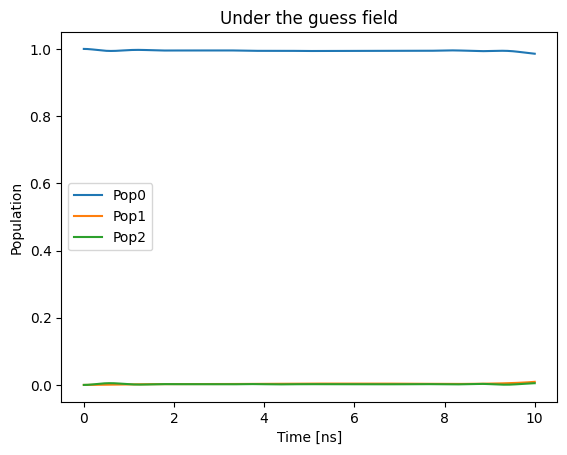

In [8]:
plot_population(tgrid, psi[0, :, :], 'Under the guess field')

Perform the fields optimization.

In [21]:
#Perform the first iteration only to compile the functions.
alf = prms["alpha"]
initerr = J_T(psi, psi_tgt)
krotov_iter(tgrid, midgrid, ctrl, psi, H0, ctHams, proj2, psi_tgt, S, alf)

maxiter = prms["maxiter"]
tol = prms["tol"]
k=2
err = 1.0
errn = J_T(psi, psi_tgt)
record = np.zeros(maxiter); record[0] = initerr; record[1] = errn#/initerr

# Perform the Krotov iterations
t_start = time.perf_counter()
while (k < maxiter and abs(errn) > tol):#  and errn <err and abs(errn/err - 1) > 1.e-4
    krotov_iter(tgrid, midgrid, ctrl, psi, H0, ctHams, proj2, psi_tgt, S, alf)
    #err = errn
    errn = J_T(psi, psi_tgt)
    record[k] = errn#/initerr
    k = k+1
    #if (abs(errn/err - 1) < 1.e-3):
    #    alf *= 2

t_end = time.perf_counter()
tempo_total = t_end - t_start

print("Final value of the functional: ", errn)
print("Number of iterations: ", k)
print(f"Elapsed time: {tempo_total} s")

Final value of the functional:  3.344601064103614e-06
Number of iterations:  200
Elapsed time: 9.85541574999661 s


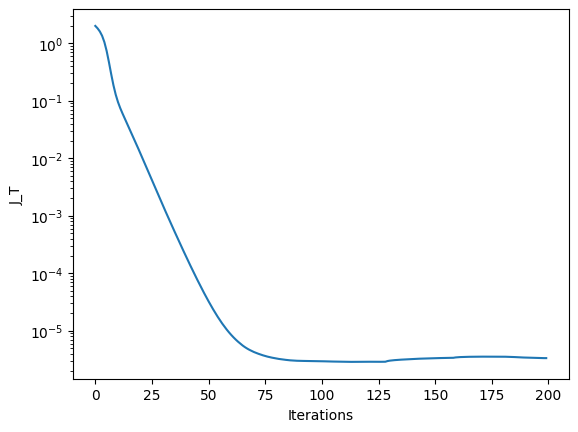

In [29]:
fig, ax = plt.subplots()
ax.plot(record[:k])
#ax.set_xlim(2, 150)
#ax.set_ylim(0.1, 1)
ax.set_xlabel('Iterations')
ax.set_ylabel('J_T')
ax.set_yscale('log')
plt.show(fig)

In [30]:
df_from_numpy = pd.DataFrame(record)

# Exporting the NumPy-based DataFrame
df_from_numpy.to_csv('Data/JT_iters_Kr_Gate_3levs_q0.csv', index=False, header=['J_T(iter)'])

In [ ]:
#print(np.abs(errn/err -1.))
print(record.min(), np.argmin(record))

0.002360408545083459 1019


Occupancies at final time: [5.076E-01 4.924E-01 1.386E-05]


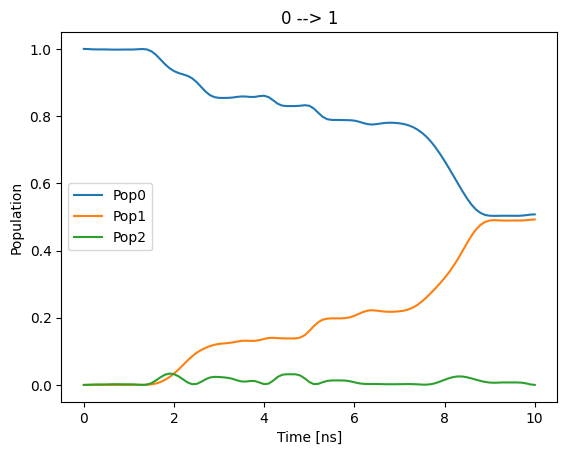

In [21]:
plot_population(tgrid, psi[0, :, :], '0 --> 1')

Occupancies at final time: [4.924E-01 5.076E-01 6.957E-06]


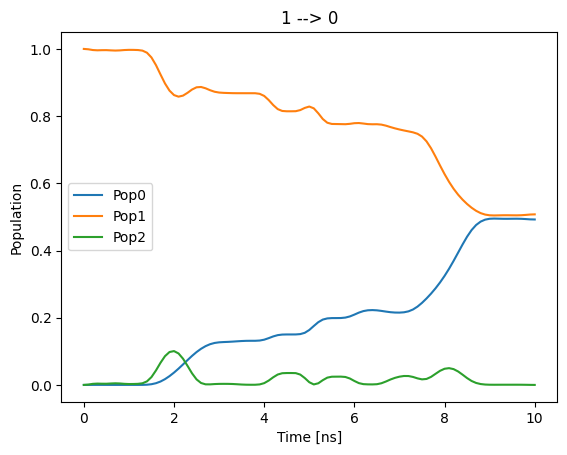

In [22]:
plot_population(tgrid, psi[1, :, :], '1 --> 0')

/tmp/ipykernel_33676/2455386850.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


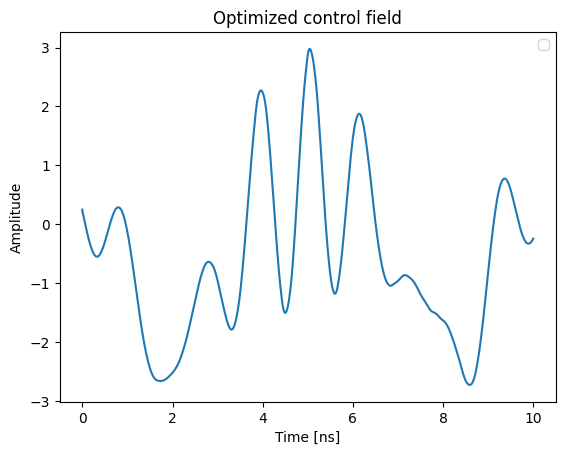

In [31]:
fig, ax = plt.subplots()
if (Thrlev):
  ax.plot(midgrid, ctrl[:,0])
else:
  ax.plot(midgrid, ctrl[:,0], label='$\\Omega_p$')
  ax.plot(midgrid, ctrl[:,1], label='$\\Omega_m$')
  
ax.set_xlabel('Time [ns]')
ax.set_ylabel('Amplitude')
ax.set_title('Optimized control field')
#ax.set_xlim(Tf-100*dt, Tf)
plt.legend()
plt.show(fig)

In [ ]:
merged = np.vstack((midgrid, ctrl.T))    
df_from_numpy = pd.DataFrame(merged.T)

if (Thrlev):
  header = ['Time'] + [f"Amp"]
else:
  header = ['Time'] + [f"Amp+"] + [f"Amp-"]

# Exporting the NumPy-based DataFrame
df_from_numpy.to_csv('Data/OptFieldKr_X_GATE_3levs_q0.csv', index=False, header=header)

In [4]:
df = pd.read_csv('Data/OptFieldKr_X_GATE_3levs_q0.csv')
iterfid = pd.read_csv('Data/JT_iters_Kr_Gate_3levs_q0.csv')
record = iterfid.to_numpy().flatten()
ctrl = (df.iloc[:, 1:]).to_numpy().copy()
midgrid = (df.iloc[:, 0]).to_numpy().copy()
Tf = midgrid[-1]
dt = midgrid[2]-midgrid[1]
N = len(midgrid)-2
tgrid = midgrid[1:] - 0.5*dt*np.ones(N+1)
tgrid[-1] = Tf
Nctrls = ctrl.shape[1]

Compute mean fidelity dynamics.

In [5]:
avrfid = np.zeros(N+1)
leakage_dyn = np.zeros(N)
int_pop = 0.
nsamp = 500


for i in range(nsamp):
    I_i = 0.0
    phi = ( (np.random.randn() + 1j*np.random.randn())*qt.basis(dim, 0) + (np.random.randn() + 1j*np.random.randn())*qt.basis(dim, 1)).unit().full().flatten()
    psitarget= Utgt @ phi
    avrfid[0] += np.abs(phi.conj().T @ psitarget)**2
    p0 = np.abs(phi[-1])**2
    for k in range(N):
        Htot = H0.copy()
        for j in range(Nctrls):
            Htot += ctrl[k + 1, j] * ctHams[j]
        
        U = expm(-1j * Htot * dt)
        phi = (U @ phi.T).T
        avrfid[k+1] += np.abs(phi.conj().T @ psitarget)**2
        pk = np.abs(phi[-1])**2
        leakage_dyn[k] += pk

        # Simpson weights
        if k == 0:
            I_i += p0 + pk
        elif k % 2 == 1:
            I_i += 4 * pk
        else:
            I_i += 2 * pk

    I_i *= dt / 3
    int_pop += I_i

avrfid /= nsamp
int_pop /= nsamp
leakage_dyn /= nsamp

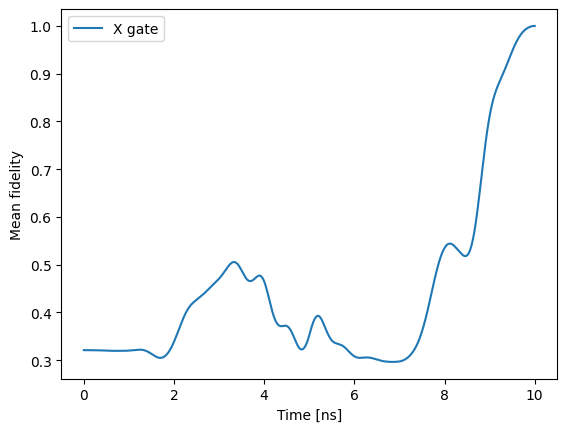

In [6]:
fig, ax = plt.subplots()
plt.plot(tgrid, avrfid, label = f'{prms["Ugate"]} gate')
ax.set_xlabel('Time [ns]')
ax.set_ylabel('Mean fidelity')
plt.legend()
plt.show()

In [32]:
avrfid[-1]

np.float64(0.9992687501791411)

Load the data files and make publication-ready figures.

In [14]:
datfile = np.loadtxt('Data/OptimizedField_Xgate_PRONTO_reg.txt')
midgrid = datfile[:,0]
ctrl = datfile[:,1:]
record = np.loadtxt('Data/Fid_vs_iters_Xgate_PRONTO_reg.txt')

Tf = midgrid[-1]
dt = midgrid[2]-midgrid[1]
N = len(midgrid)-2
tgrid = midgrid[1:] - 0.5*dt*np.ones(N+1)
tgrid[-1] = Tf

In [15]:
psi = np.zeros((len(psi0), dim, N + 1), dtype=complex)
for i in range(psi.shape[0]):
    psi[i, :, 0] = psi0[i].flatten()

# Evolve under the guess control field
for i in range(tgrid.shape[0]-1):
    Htot = H0.copy()
    for j in range(Nctrls):
        Htot += ctrl[i + 1, j] * ctHams[j]
    U = expm(-1j * Htot * dt)
    for k in range(len(psi0)):
        psi[k, :, i + 1] = (U @ psi[k, :, i].T).T

In [8]:
from matplotlib.ticker import LogLocator, NullFormatter

/tmp/ipykernel_35033/603168626.py:85: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax_c.legend(loc='upper center', frameon=False, edgecolor='black', facecolor='white', framealpha=1)


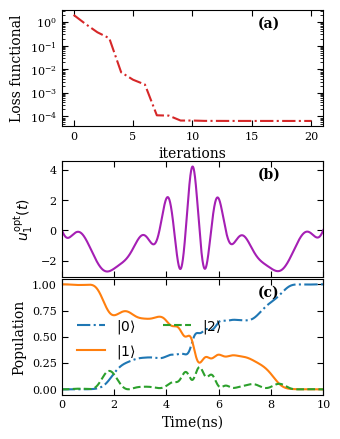

In [16]:
#outfilename = 'figs/Krotov_GateError_3levels_no_leakage.pdf'
outfilename = 'figs/PRONTO_GateError_3levels_no_leakage.pdf'

# 1. Parâmetros APS sem LaTeX nativo (Usa o mathtext interno para evitar erros)
aps_params = {
    "text.usetex": False,              
    "font.family": "serif",            
    "font.serif": ["DejaVu Serif", "Computer Modern Roman"],
    "font.size": 10,                   
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "axes.linewidth": 0.8,
    "xtick.direction": "in",           
    "ytick.direction": "in",
    "xtick.major.size": 4,
    "ytick.major.size": 4,
    "xtick.minor.size": 2,             
    "ytick.minor.size": 2,
    "xtick.top": True,                 
    "ytick.right": True,
    "pdf.fonttype": 42
}
plt.rcParams.update(aps_params)

# 3. Criando a malha de subfiguras usando GridSpec
# Largura total APS de duas colunas: 6.75 polegadas. Altura proporcional: 3.0 polegadas.
fig = plt.figure(figsize=(3.375, 5.0))
#gs = fig.add_gridspec(2, 2, width_ratios=[1, 1], height_ratios=[1, 1])
gs = fig.add_gridspec(
    2, 1,
    height_ratios=[1, 2],   # (a) ocupa 1 parte; (b)+(c) ocupam 2 partes
    hspace=0.2             # espaço entre (a) e o bloco inferior
)

gs_bottom = gs[1].subgridspec(
    2, 1,
    hspace=0.02             # quase colados
)


# --- Subfigura A (Canto superior esquerdo) ---
ax_a = fig.add_subplot(gs_bottom[0])
ax_a.plot(midgrid, ctrl[:,0], color="#a51fb4")
# Oculta os rótulos do eixo X da figura de cima já que eles compartilham o mesmo eixo
ax_a.tick_params(labelbottom=False) 
ax_a.set_ylabel(r'$u_1^{\text{opt}}(t)$')
ax_a.set_xlim(0, 10)
ax_a.text(0.75, 0.85, '(b)', transform=ax_a.transAxes, weight='bold') # Identificador clássico da APS

# --- Subfigura B (Canto inferior esquerdo - Compartilha o X com a de cima) ---
ax_b = fig.add_subplot(gs_bottom[1], sharex=ax_a)
basis = [qt.basis(dim, k).full() for k in range(dim)]
ocs = np.zeros((N + 1, dim))
for i in range(N + 1):
    for j in range(dim):
        ocs[i, j] = np.abs(np.vdot(basis[j].flatten(), psi[1, :, i]))**2

ax_b.plot(tgrid, ocs[:,0], label=r'$|0\rangle$', linestyle='-.')
ax_b.plot(tgrid, ocs[:,1], label=r'$|1\rangle$', linestyle='-')
ax_b.plot(tgrid, ocs[:,2], label=r'$|2\rangle$', linestyle='--')

# Oculta os rótulos do eixo X da figura de cima já que eles compartilham o mesmo eixo
ax_b.set_ylabel(r'Population')
ax_b.set_xlabel(r'Time(ns)')
ax_b.set_xlim(0, 10)
ax_b.text(0.75, 0.85, '(c)', transform=ax_b.transAxes, weight='bold')
ax_b.legend(loc='lower left', ncol=2,frameon=False, edgecolor='black', facecolor='white', framealpha=1
            , bbox_to_anchor=(0.01, .19, 0.8, 0.5))

# --- Subfigura C (Lado direito completo - Ocupa as duas linhas da coluna 1) ---
ax_c = fig.add_subplot(gs[0])
ax_c.plot(record[:21], color='#d62728', linestyle='-.')
ax_c.set_yscale('log') # Escala Log no eixo Y conforme seu pedido anterior
ax_c.set_xlabel(r'iterations')
ax_c.set_ylabel(r'Loss functional')
# ax_c.set_xlim(1, 100)

# Ajuste fino dos minor ticks logarítmicos na subfigura distinta
ax_c.yaxis.set_major_locator(LogLocator(base=10.0, numticks=10))
ax_c.yaxis.set_minor_locator(LogLocator(base=10.0, subs=(0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9), numticks=12))
ax_c.yaxis.set_minor_formatter(NullFormatter())
ax_c.text(0.75, 0.85, '(a)', transform=ax_c.transAxes, weight='bold')
ax_c.legend(loc='upper center', frameon=False, edgecolor='black', facecolor='white', framealpha=1)

# 4. Salvar o arquivo finalizado
# 'constrained_layout' ou hspace/wspace manual são essenciais para evitar sobreposição de textos
plt.subplots_adjust(hspace=0.1, wspace=0.32)
plt.savefig(outfilename, bbox_inches='tight', pad_inches=0.02)
plt.show()